In [2]:
import re, zipfile, glob
from pathlib import Path
from collections import Counter

zips = [Path(p) for p in glob.glob(r"D:\Downloads\*.zip")]
for z in zips:
    print(z.name, round(z.stat().st_size / 1e9, 2), "GB")

ZIP = next(p for p in zips if "UAlpha40" in p.name)      # naam se dataset ki zip chunte hain
print("\nistemal:", ZIP.name)

zf = zipfile.ZipFile(ZIP)
names = [n for n in zf.namelist() if not n.endswith("/")]
print("files:", len(names))

dirs = Counter("/".join(n.split("/")[:-1]) for n in names)
print("folders:", len(dirs))
for d in list(dirs)[:12]:
    print(" ", dirs[d], d)

aug_dirs = [d for d in dirs if "ugment" in d.lower()]
print("\naugmented folders:", len(aug_dirs))
prefixes = tuple(d + "/" for d in aug_dirs)
aug_files = [n for n in names if n.startswith(prefixes)]
has_id = [bool(re.match(r"s\d{4}", n.split("/")[-1], re.I)) for n in aug_files]
print("augmented files:", len(aug_files), "| jin ke naam sXXXX se shuru:", sum(has_id))
print("\nnamune:")
for n in aug_files[:4]:
    print(" ", n)

mcq-answerer.zip 0.0 GB
screen-answer-share.zip 0.0 GB
UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language.zip 5.65 GB

istemal: UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language.zip
files: 22672
folders: 76
  578 UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language/1-Hay-Augmented
  81 UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language/1-Hay-Original
  87 UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language/2-Hay
  506 UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language/Ain-Augmented
  79 UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language/Ain-Original
  579 UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language/Alif-Augmented
  81 UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language/Alif-Original
  105 UAlpha40 A Comprehensive Dataset of Urdu alphabets for 

In [3]:
import numpy as np, pandas as pd, time, tempfile, sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.landmarks import extract_landmarks

def sid(x):                                   # "s0251" / "0251" / 251 -> "0251"
    return re.search(r"(\d+)", str(x)).group(1).zfill(4)

train = pd.read_csv(ROOT / "data/processed/train.csv")
test = pd.read_csv(ROOT / "data/processed/test.csv")
train_sig = {sid(s) for s in train["signer_id"]}
test_sig = {sid(s) for s in test["signer_id"]}
print("train signers:", len(train_sig), "| test signers:", len(test_sig),
      "| overlap:", len(train_sig & test_sig))

rows = []
for n in aug_files:
    parts = n.split("/")
    rows.append({"zip_path": n,
                 "label": parts[-2].replace("-Augmented", ""),
                 "signer_id": re.match(r"s(\d{4})", parts[-1], re.I).group(1),
                 "filename": parts[-1]})
aug = pd.DataFrame(rows)
aug["split"] = np.where(aug.signer_id.isin(train_sig), "train",
                np.where(aug.signer_id.isin(test_sig), "test", "none"))
print(aug["split"].value_counts())

# --- sirf ek harf (Lam) ka waqt ka test ---
sel = aug[(aug.split == "train") & (aug.label == "Lam")]
print(len(sel), "Lam ki train-signer augmented images")
t0 = time.time()
out = []
with tempfile.TemporaryDirectory() as tmp:
    p = Path(tmp) / "x.jpg"
    for r in sel.itertuples():
        p.write_bytes(zf.read(r.zip_path))
        lm = extract_landmarks(p)
        if lm is not None:
            out.append([r.label, r.signer_id, r.filename] + list(lm))
print(f"{time.time() - t0:.1f} sec | kamyab: {len(out)} / {len(sel)}")

train signers: 66 | test signers: 16 | overlap: 0
split
train    13795
test      5516
none        72
Name: count, dtype: int64
360 Lam ki train-signer augmented images
17.7 sec | kamyab: 345 / 360


In [4]:
parts_dir = ROOT / "data/processed/aug_parts"
parts_dir.mkdir(parents=True, exist_ok=True)
cols = ["label", "signer_id", "filename"] + [f"f{i}" for i in range(63)]

todo = aug[aug.split == "train"]                      # sirf train signers
assert set(todo.signer_id).isdisjoint(test_sig), "test signer ghus gaya!"
print("istemal hone wali images:", len(todo))

t0 = time.time()
with tempfile.TemporaryDirectory() as tmp:
    p = Path(tmp) / "x.jpg"
    for label, grp in todo.groupby("label"):
        f = parts_dir / f"{label}.csv"
        if f.exists():
            continue                                  # pehle ho chuka, chhor do (resume)
        out = []
        for r in grp.itertuples():
            p.write_bytes(zf.read(r.zip_path))
            lm = extract_landmarks(p)
            if lm is not None:
                out.append([r.label, r.signer_id, r.filename] + list(lm))
        pd.DataFrame(out, columns=cols).to_csv(f, index=False)
        print(f"{label:10s} {len(out):4d}/{len(grp):4d}   {time.time() - t0:6.0f} sec")

aug_lm = pd.concat([pd.read_csv(f, dtype={"signer_id": str})
                    for f in sorted(parts_dir.glob("*.csv"))], ignore_index=True)
aug_lm.to_csv(ROOT / "data/processed/aug_landmarks.csv", index=False)
print("\nkul:", aug_lm.shape, "| harf:", aug_lm.label.nunique())

istemal hone wali images: 13795
1-Hay       374/ 408       17 sec
Ain         311/ 360       34 sec
Alif        344/ 408       51 sec
Bay         380/ 414       67 sec
Byeh        335/ 360       84 sec
Chay        327/ 377      101 sec
Cyeh        333/ 360      115 sec
Daal        345/ 408      133 sec
Dal         323/ 360      147 sec
Dochahay    280/ 359      160 sec
Fay         351/ 360      176 sec
Gaaf        341/ 360      191 sec
Ghain       294/ 360      206 sec
Hamza       327/ 360      224 sec
Kaf         281/ 360      238 sec
Khay        344/ 384      256 sec
Kiaf        342/ 360      272 sec
Lam         345/ 360      291 sec
Meem        293/ 360      308 sec
Nuun        278/ 355      321 sec
Nuungh      349/ 360      337 sec
Pay         329/ 402      353 sec
Ray         402/ 432      371 sec
Say         323/ 385      387 sec
Seen        334/ 432      402 sec
Sheen       286/ 432      417 sec
Suad        379/ 432      435 sec
Taay        279/ 408      450 sec
Tay         166/

Cell A

In [5]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from src.features import normalize_landmarks, add_engineered_features

feat_cols = [f"f{i}" for i in range(63)]
Xo = train[feat_cols].to_numpy(dtype=np.float64)
yo = train["label"].astype(str).to_numpy()
go = np.array([sid(s) for s in train["signer_id"]])

Xa_raw = aug_lm[feat_cols].to_numpy(dtype=np.float64)
Xa = np.vstack([normalize_landmarks(r) for r in Xa_raw])      # originals jaisi hi normalization
ya = aug_lm["label"].astype(str).to_numpy()
ga = aug_lm["signer_id"].astype(str).str.zfill(4).to_numpy()

print("originals:", Xo.shape, "| augmented:", Xa.shape)
print("wrist max (0 hona chahiye):", np.abs(Xa[:, :3]).max())
print("harf same?", set(yo) == set(ya))
print("augmented signers, train signers mein se?", set(ga) <= set(go))
print("augmented signers, test signers se tou nahi?", set(ga).isdisjoint(test_sig))
print("\nsabse kam augmented wale harf:")
print(aug_lm.label.value_counts().tail(5).to_string())

originals: (2165, 63) | augmented: (11821, 63)
wrist max (0 hona chahiye): 0.0
harf same? True
augmented signers, train signers mein se? True
augmented signers, test signers se tou nahi? True

sabse kam augmented wale harf:
label
Kaf         281
Dochahay    280
Taay        279
Nuun        278
Tay         166


Cell B

In [6]:
def make_model():
    return Pipeline([("scaler", StandardScaler()),
                     ("svm", SVC(kernel="rbf", C=100, gamma=0.01))])

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
t0 = time.time()
for fold, (tr, va) in enumerate(sgkf.split(Xo, yo, go), start=1):
    tr_sig, va_sig = set(go[tr]), set(go[va])
    assert tr_sig.isdisjoint(va_sig)
    keep = np.isin(ga, list(tr_sig))                      # sirf train-fold signers ki copies
    assert not np.isin(ga[keep], list(va_sig)).any()

    variants = {
        "D originals only":        (Xo[tr], yo[tr]),
        "E originals + augmented": (np.vstack([Xo[tr], Xa[keep]]),
                                    np.concatenate([yo[tr], ya[keep]])),
    }
    for name, (Xt, yt) in variants.items():
        m = make_model().fit(add_engineered_features(Xt), yt)
        p = m.predict(add_engineered_features(Xo[va]))
        rows.append({"fold": fold, "variant": name, "n_train": len(yt),
                     "acc": accuracy_score(yo[va], p),
                     "macro_f1": f1_score(yo[va], p, average="macro")})
    print(f"fold {fold} done | {time.time() - t0:.0f} sec")

res4 = pd.DataFrame(rows)
print(res4.groupby("variant")[["n_train", "acc", "macro_f1"]].mean().round(4))
res4.to_csv(ROOT / "results/advanced_augmented_cv.csv", index=False)
print(res4.pivot(index="fold", columns="variant", values="acc").round(4))

fold 1 done | 2 sec
fold 2 done | 3 sec
fold 3 done | 5 sec
fold 4 done | 6 sec
fold 5 done | 7 sec
                         n_train     acc  macro_f1
variant                                           
D originals only          1732.0  0.9458    0.9435
E originals + augmented  11188.8  0.9468    0.9446
variant  D originals only  E originals + augmented
fold                                              
1                  0.9512                   0.9535
2                  0.9416                   0.9369
3                  0.9329                   0.9424
4                  0.9506                   0.9438
5                  0.9528                   0.9573


Cell C

In [7]:
Xte = test[feat_cols].to_numpy(dtype=np.float64)
yte = test["label"].astype(str).to_numpy()

out = []
for name, (Xt, yt) in {"D originals only": (Xo, yo),
                       "E originals + augmented": (np.vstack([Xo, Xa]),
                                                   np.concatenate([yo, ya]))}.items():
    m = make_model().fit(add_engineered_features(Xt), yt)
    p = m.predict(add_engineered_features(Xte))
    out.append({"variant": name, "n_train": len(yt),
                "test_acc": accuracy_score(yte, p),
                "test_macro_f1": f1_score(yte, p, average="macro")})
out = pd.DataFrame(out).round(4)
print(out.to_string(index=False))
out.to_csv(ROOT / "results/advanced_augmented_test.csv", index=False)

                variant  n_train  test_acc  test_macro_f1
       D originals only     2165    0.9413         0.9371
E originals + augmented    13986    0.9520         0.9501


original ka naam: s0252-31lam
is original ki copies: 24
original file: ['UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language/Lam-Original/s0252-31lam.JPG']


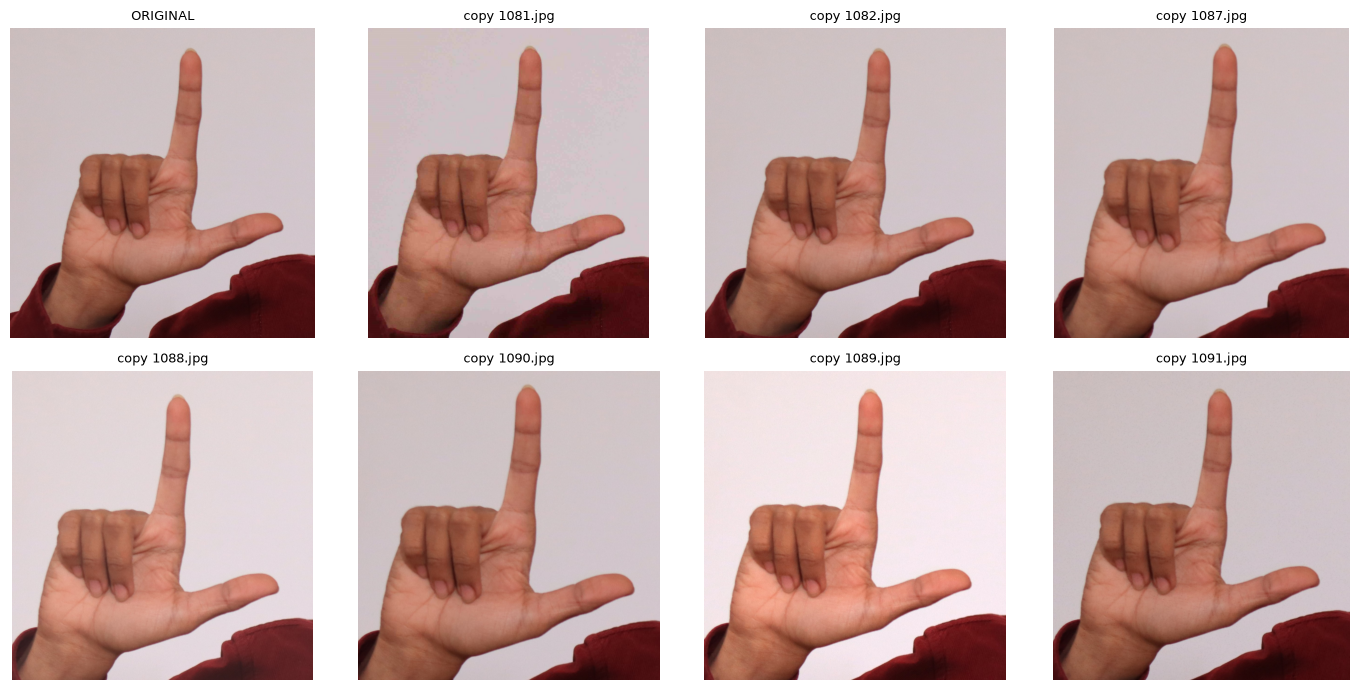

In [8]:
import io
import matplotlib.pyplot as plt
from PIL import Image

sample = aug[(aug.label == "Lam") & (aug.split == "train")].iloc[0]
base = re.sub(r"-Generated-\d+.*$", "", sample.filename, flags=re.I)
print("original ka naam:", base)

copies = aug[(aug.label == "Lam") & (aug.filename.str.startswith(base + "-Generated"))]
print("is original ki copies:", len(copies))

orig = [n for n in names if "-Original/" in n
        and n.split("/")[-1].lower().startswith(base.lower())]
print("original file:", orig[:1])

paths = orig[:1] + list(copies.zip_path[:7])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, pth in zip(axes.ravel(), paths):
    ax.imshow(Image.open(io.BytesIO(zf.read(pth))))
    ax.set_title("ORIGINAL" if "-Original/" in pth else "copy " + pth.split("-Generated-")[-1], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [9]:
def mirror(X):
    Xm = X.copy()
    Xm[:, 0::3] *= -1
    return Xm

rows = []
t0 = time.time()
for fold, (tr, va) in enumerate(sgkf.split(Xo, yo, go), start=1):
    tr_sig, va_sig = set(go[tr]), set(go[va])
    assert tr_sig.isdisjoint(va_sig)
    keep = np.isin(ga, list(tr_sig))                       # sirf train-fold signers ki copies
    assert not np.isin(ga[keep], list(va_sig)).any()

    variants = {
        "C v3: eng93 + mirror":              (Xo[tr], yo[tr]),
        "F v4: eng93 + mirror + augmented":  (np.vstack([Xo[tr], Xa[keep]]),
                                              np.concatenate([yo[tr], ya[keep]])),
    }
    for name, (Xt, yt) in variants.items():
        Xt_m = np.vstack([Xt, mirror(Xt)])
        yt_m = np.concatenate([yt, yt])
        m = make_model().fit(add_engineered_features(Xt_m), yt_m)
        for side, Xv in [("right", Xo[va]), ("left", mirror(Xo[va]))]:
            p = m.predict(add_engineered_features(Xv))
            rows.append({"fold": fold, "variant": name, "hand": side,
                         "n_train": len(yt_m),
                         "acc": accuracy_score(yo[va], p),
                         "macro_f1": f1_score(yo[va], p, average="macro")})
    print(f"fold {fold} done | {time.time() - t0:.0f} sec")

res5 = pd.DataFrame(rows)
print(res5.groupby(["variant", "hand"])[["n_train", "acc", "macro_f1"]].mean().round(4))
res5.to_csv(ROOT / "results/advanced_v4_cv.csv", index=False)
print(res5[res5.hand == "right"].pivot(index="fold", columns="variant", values="acc").round(4))

fold 1 done | 4 sec
fold 2 done | 9 sec
fold 3 done | 15 sec
fold 4 done | 19 sec
fold 5 done | 25 sec
                                        n_train     acc  macro_f1
variant                          hand                            
C v3: eng93 + mirror             left    3464.0  0.9499    0.9479
                                 right   3464.0  0.9499    0.9479
F v4: eng93 + mirror + augmented left   22377.6  0.9509    0.9487
                                 right  22377.6  0.9509    0.9487
variant  C v3: eng93 + mirror  F v4: eng93 + mirror + augmented
fold                                                           
1                      0.9535                            0.9535
2                      0.9439                            0.9416
3                      0.9376                            0.9448
4                      0.9618                            0.9551
5                      0.9528                            0.9596


In [10]:
import joblib
from sklearn.preprocessing import FunctionTransformer
from src.features import add_engineered_features as eng_src

X_all = np.vstack([Xo, Xa])
y_all = np.concatenate([yo, ya])
X_fit = np.vstack([X_all, mirror(X_all)])
y_fit = np.concatenate([y_all, y_all])

final_v4 = Pipeline([("eng", FunctionTransformer(eng_src)),
                     ("scaler", StandardScaler()),
                     ("svm", SVC(kernel="rbf", C=100, gamma=0.01,
                                 probability=True, random_state=42))])
t0 = time.time()
final_v4.fit(X_fit, y_fit)
print(f"v4 train: {time.time() - t0:.0f} sec | samples: {len(y_fit)}")

v3 = joblib.load(ROOT / "models/best_model_v3_eng.joblib")
Xte = test[feat_cols].to_numpy(dtype=np.float64)
yte = test["label"].astype(str).to_numpy()

out = []
for name, m in {"v3 (93 + mirror)": v3, "v4 (93 + mirror + augmented)": final_v4}.items():
    for side, Xt in [("right", Xte), ("left", mirror(Xte))]:
        p = m.predict(Xt)
        out.append({"model": name, "hand": side,
                    "test_acc": accuracy_score(yte, p),
                    "test_macro_f1": f1_score(yte, p, average="macro")})
out = pd.DataFrame(out).round(4)
print(out.to_string(index=False))

out.to_csv(ROOT / "results/advanced_v4_test.csv", index=False)
joblib.dump(final_v4, ROOT / "models/best_model_v4_aug.joblib")
print("model file size (MB):", round((ROOT / "models/best_model_v4_aug.joblib").stat().st_size / 1e6, 1))

d:\CS 5 Course\ML(Lab)\Project\psl-translator\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


v4 train: 23 sec | samples: 27972
                       model  hand  test_acc  test_macro_f1
            v3 (93 + mirror) right    0.9324         0.9277
            v3 (93 + mirror)  left    0.9324         0.9277
v4 (93 + mirror + augmented) right    0.9448         0.9426
v4 (93 + mirror + augmented)  left    0.9448         0.9426
model file size (MB): 5.5
